# Σύστημα Β – Βήμα 2: νευρωνικό δίκτυο και σύγκριση με τον απλό κανόνα
Στο B01 είδαμε ότι ένας κανόνας με λίγες ερωτήσεις πιάνει τις περισσότερες επιθέσεις χωρίς ψευδείς συναγερμούς, και ότι το `browser_type` προσθέτει πληροφορία (9 είσοδοι).

1. Μοντέλα αναφοράς (ο κανόνας και τα κλασικά).
2. Νευρωνικό δίκτυο: 9 εκδοχές (3 μεγέθη × 3 τιμές dropout), η καθεμία με 3 σπόρους.
3. Σύγκριση στο validation.
4. Το ίδιο δίκτυο με 8 και με 9 εισόδους.
5. Προσθέτει κάτι το δίκτυο πέρα από τον κανόνα;

Όλα μετρώνται στο **validation**. Το test δεν χρησιμοποιείται. Χρόνος: περίπου 10–20 λεπτά (30 μικρές εκπαιδεύσεις).

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from keras import layers
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, recall_score

DATA, MODELS, FIG = "../data/", "../models/", "../figures/"
SEED = 42

d = np.load(DATA + "intrusion_prepared.npz")
with open(MODELS + "intrusion_meta.json", encoding="utf-8") as f:
    meta = json.load(f)
assert "browser_type" in meta["cat_cols"], "Τα δεδομένα είναι από το παλιό B01 (8 είσοδοι) – τρέξε πρώτα το νέο B01"
X = {s: d[f"X_{s}"] for s in ("train", "val")}
y = {s: d[f"y_{s}"].astype(int) for s in ("train", "val")}
short = [f.split("__")[-1] for f in meta["feature_names"]]
print("Σχήματα:", {s: X[s].shape for s in X})
print("Είσοδοι δικτύου:", short)

def metrics(y_true, p):
    pred = p >= 0.5
    return {"accuracy": accuracy_score(y_true, pred), "ROC-AUC": roc_auc_score(y_true, p),
            "recall (επιθέσεις)": recall_score(y_true, pred),
            "FPR (ψευδείς συναγερμοί)": ((pred == 1) & (y_true == 0)).sum() / (y_true == 0).sum()}

Σχήματα: {'train': (6675, 17), 'val': (1431, 17)}
Είσοδοι δικτύου: ['session_duration', 'network_packet_size', 'login_attempts', 'ip_reputation_score', 'failed_logins', 'unusual_time_access', 'protocol_type_ICMP', 'protocol_type_TCP', 'protocol_type_UDP', 'encryption_used_AES', 'encryption_used_DES', 'encryption_used_None', 'browser_type_Chrome', 'browser_type_Edge', 'browser_type_Firefox', 'browser_type_Safari', 'browser_type_Unknown']


## Β2.1 Μοντέλα αναφοράς
Τα ίδια με το B01, για να μπουν στον ίδιο πίνακα με το νευρωνικό. Ο «κανόνας 3 ερωτήσεων» είναι το δέντρο απόφασης βάθους 3.

In [2]:
rule = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X["train"], y["train"])
RULE = "Κανόνας 3 ερωτήσεων (δέντρο βάθους 3)"
reference = {RULE: rule,
             "Δέντρο βάθους 5": DecisionTreeClassifier(max_depth=5, random_state=SEED).fit(X["train"], y["train"]),
             "Logistic Regression": LogisticRegression(max_iter=1000).fit(X["train"], y["train"]),
             "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED).fit(X["train"], y["train"]),
             "Gradient Boosting": GradientBoostingClassifier(random_state=SEED).fit(X["train"], y["train"])}
p_val = {name: m.predict_proba(X["val"])[:, 1] for name, m in reference.items()}
results = {name: metrics(y["val"], p) for name, p in p_val.items()}
rule_pred = rule.predict(X["val"])
print(pd.DataFrame(results).T.round(4).to_string())

                                       accuracy  ROC-AUC  recall (επιθέσεις)  FPR (ψευδείς συναγερμοί)
Κανόνας 3 ερωτήσεων (δέντρο βάθους 3)    0.8665   0.8508              0.7016                    0.0000
Δέντρο βάθους 5                          0.8847   0.8757              0.7422                    0.0000
Logistic Regression                      0.7268   0.7844              0.6516                    0.2124
Random Forest                            0.8805   0.8735              0.7484                    0.0126
Gradient Boosting                        0.8889   0.8756              0.7516                    0.0000


## Β2.2 Νευρωνικό δίκτυο
Ένα απλό MLP με μία έξοδο (πιθανότητα επίθεσης). Δοκιμάζουμε από την αρχή διάφορα μεγέθη και dropout, και κάθε εκδοχή με 3 σπόρους,
ώστε η επιλογή να μη στηρίζεται σε μία τυχαία εκπαίδευση (το μάθημα από το Σύστημα Α).

- **Μέγεθος:** 16 · 32-16 · 64-32 νευρώνες. Το πρόβλημα είναι μικρό (6.675 γραμμές), δεν χρειάζεται μεγάλο δίκτυο.
- **Dropout:** 0.0 · 0.1 · 0.3.
- **Κριτήριο επιλογής:** μέσο ROC-AUC στο validation σε 3 σπόρους. Η ακρίβεια εδώ δεν ξεχωρίζει τα μοντέλα, ενώ το ROC-AUC δείχνει και πόσο καλά κατατάσσει το δίκτυο τις ροές.

In [3]:
UNITS = {"16": (16,), "32-16": (32, 16), "64-32": (64, 32)}
DROPOUTS = [0.0, 0.1, 0.3]
SEEDS = [42, 7, 123]

def build_model(n_features, units, dropout, lr=1e-3):
    inp = keras.Input(shape=(n_features,), name="session_features")
    x = inp
    for i, u in enumerate(units):
        x = layers.Dense(u, activation="relu", name=f"dense_{i+1}")(x)
        x = layers.BatchNormalization(name=f"bn_{i+1}")(x)
        x = layers.Dropout(dropout, name=f"dropout_{i+1}")(x)
    out = layers.Dense(1, activation="sigmoid", name="attack")(x)
    model = keras.Model(inp, out, name="intrusion_mlp")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy")
    return model

def train(units, dropout, seed, cols=None):
    """Εκπαιδεύει ένα δίκτυο. cols: ποιες στήλες εισόδου χρησιμοποιούνται (None = όλες)."""
    Xt = X["train"] if cols is None else X["train"][:, cols]
    Xv = X["val"] if cols is None else X["val"][:, cols]
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    model = build_model(Xt.shape[1], units, dropout)
    history = model.fit(Xt, y["train"].astype("float32"), validation_data=(Xv, y["val"].astype("float32")),
                        epochs=200, batch_size=128, verbose=0,
                        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
                                   keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)])
    return model, model.predict(Xv, batch_size=1024, verbose=0).ravel(), len(history.history["loss"])

runs, weights, probs = [], {}, {}
for u_name, units in UNITS.items():
    for dr in DROPOUTS:
        for seed in SEEDS:
            model, p, epochs = train(units, dr, seed)
            runs.append({"μέγεθος": u_name, "dropout": dr, "σπόρος": seed, "εποχές": epochs, **metrics(y["val"], p)})
            if seed == SEED:
                weights[(u_name, dr)], probs[(u_name, dr)] = model.get_weights(), p
        last = pd.DataFrame(runs[-len(SEEDS):])
        print(f"{u_name:>6}, dropout {dr}: accuracy {last['accuracy'].mean():.4f} ± {last['accuracy'].std():.4f} | "
              f"ROC-AUC {last['ROC-AUC'].mean():.4f} ± {last['ROC-AUC'].std():.4f}")

runs = pd.DataFrame(runs)
runs.to_csv(MODELS + "intrusion_tuning.csv", index=False)
grid = runs.groupby(["μέγεθος", "dropout"], sort=False)[["accuracy", "ROC-AUC", "recall (επιθέσεις)", "FPR (ψευδείς συναγερμοί)"]].agg(["mean", "std"])
BEST = grid[("ROC-AUC", "mean")].idxmax()
print(f"\nΕπιλογή (μέγιστο μέσο ROC-AUC στο validation): μέγεθος {BEST[0]}, dropout {BEST[1]}")
print(grid.round(4).to_string())


    16, dropout 0.0: accuracy 0.8828 ± 0.0011 | ROC-AUC 0.8681 ± 0.0038
    16, dropout 0.1: accuracy 0.8842 ± 0.0004 | ROC-AUC 0.8730 ± 0.0019
    16, dropout 0.3: accuracy 0.8842 ± 0.0004 | ROC-AUC 0.8689 ± 0.0026
 32-16, dropout 0.0: accuracy 0.8730 ± 0.0011 | ROC-AUC 0.8616 ± 0.0041
 32-16, dropout 0.1: accuracy 0.8831 ± 0.0004 | ROC-AUC 0.8714 ± 0.0057
 32-16, dropout 0.3: accuracy 0.8840 ± 0.0000 | ROC-AUC 0.8704 ± 0.0025
 64-32, dropout 0.0: accuracy 0.8637 ± 0.0025 | ROC-AUC 0.8692 ± 0.0048
 64-32, dropout 0.1: accuracy 0.8796 ± 0.0011 | ROC-AUC 0.8683 ± 0.0058
 64-32, dropout 0.3: accuracy 0.8828 ± 0.0021 | ROC-AUC 0.8728 ± 0.0031

Επιλογή (μέγιστο μέσο ROC-AUC στο validation): μέγεθος 16, dropout 0.1
                accuracy         ROC-AUC         recall (επιθέσεις)         FPR (ψευδείς συναγερμοί)        
                    mean     std    mean     std               mean     std                     mean     std
μέγεθος dropout                                              

Αποθηκεύτηκε: models/intrusion_mlp.keras | παράμετροι: 369


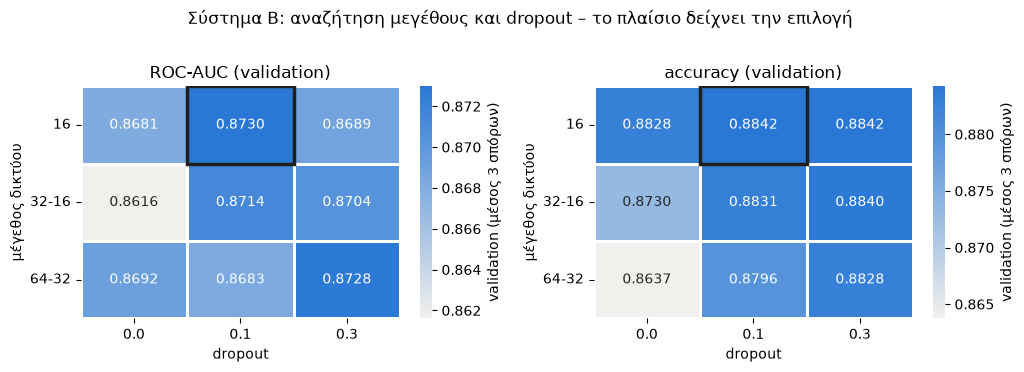

In [4]:
best_model = build_model(X["train"].shape[1], UNITS[BEST[0]], BEST[1])
best_model.set_weights(weights[BEST])                       # η εκπαίδευση με σπόρο 42 της επιλεγμένης εκδοχής
best_model.save(MODELS + "intrusion_mlp.keras")
with open(MODELS + "intrusion_mlp_config.json", "w", encoding="utf-8") as f:
    json.dump({"features": meta["features"], "units": list(UNITS[BEST[0]]), "dropout": BEST[1], "seed": SEED, "epochs_max": 200,
               "patience": 15, "batch_size": 128, "criterion": "μέσο validation ROC-AUC σε 3 σπόρους"}, f, ensure_ascii=False, indent=2)
p_nn = probs[BEST]
print("Αποθηκεύτηκε: models/intrusion_mlp.keras | παράμετροι:", best_model.count_params())

SEQ_CMAP = LinearSegmentedColormap.from_list("seq", ["#f1f0ec", "#2a78d6"])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for ax, metric in zip(axes, ["ROC-AUC", "accuracy"]):
    piv = pd.DataFrame({dr: {u: grid.loc[(u, dr), (metric, "mean")] for u in UNITS} for dr in DROPOUTS})
    sns.heatmap(piv, cmap=SEQ_CMAP, annot=True, fmt=".4f", annot_kws={"size": 10}, linewidths=2, linecolor="white",
                cbar_kws={"label": "validation (μέσος 3 σπόρων)"}, ax=ax)
    ax.add_patch(Rectangle((DROPOUTS.index(BEST[1]), list(UNITS).index(BEST[0])), 1, 1, fill=False, edgecolor="#1f1f1d", linewidth=2.5))
    ax.set_title(f"{metric} (validation)"); ax.set_xlabel("dropout"); ax.set_ylabel("μέγεθος δικτύου")
    plt.setp(ax.get_yticklabels(), rotation=0)
fig.suptitle("Σύστημα Β: αναζήτηση μεγέθους και dropout – το πλαίσιο δείχνει την επιλογή", y=1.02)
plt.tight_layout(); plt.savefig(FIG + "B01_intrusion_tuning_grid.png", dpi=200, bbox_inches="tight"); plt.show()

## Β2.3 Σύγκριση στο validation
Για το νευρωνικό δίνεται η εκπαίδευση που αποθηκεύτηκε (σπόρος 42) και, από κάτω, ο μέσος και η διακύμανση στους 3 σπόρους.

                                       accuracy  ROC-AUC  recall (επιθέσεις)  FPR (ψευδείς συναγερμοί)
Κανόνας 3 ερωτήσεων (δέντρο βάθους 3)    0.8665   0.8508              0.7016                    0.0000
Δέντρο βάθους 5                          0.8847   0.8757              0.7422                    0.0000
Logistic Regression                      0.7268   0.7844              0.6516                    0.2124
Random Forest                            0.8805   0.8735              0.7484                    0.0126
Gradient Boosting                        0.8889   0.8756              0.7516                    0.0000
Νευρωνικό (16, dropout 0.1)              0.8847   0.8711              0.7422                    0.0000

Το ίδιο δίκτυο σε 3 σπόρους (μέσος ± τυπική απόκλιση):
accuracy                 mean  0.8842
                         std   0.0004
ROC-AUC                  mean  0.8730
                         std   0.0019
recall (επιθέσεις)       mean  0.7422
                         std   0.

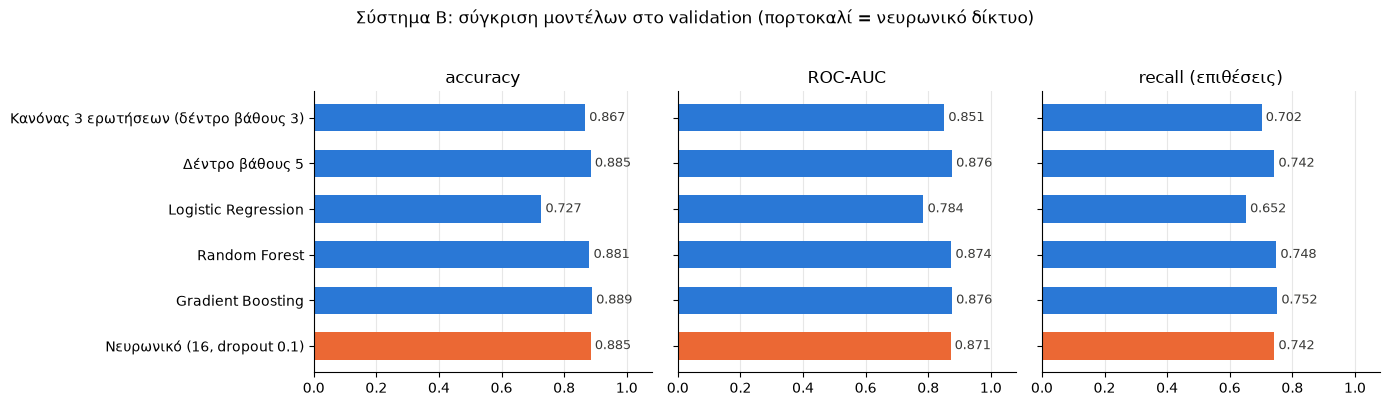

In [5]:
NN = f"Νευρωνικό ({BEST[0]}, dropout {BEST[1]})"
results[NN] = metrics(y["val"], p_nn)
comparison = pd.DataFrame(results).T.round(4)
comparison.to_csv(MODELS + "intrusion_model_comparison_validation.csv")
print(comparison.to_string())
print("\nΤο ίδιο δίκτυο σε 3 σπόρους (μέσος ± τυπική απόκλιση):")
print(grid.loc[[BEST]].round(4).T.to_string(header=False))

order = list(results)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)
for ax, metric in zip(axes, ["accuracy", "ROC-AUC", "recall (επιθέσεις)"]):
    vals = [results[m][metric] for m in order]
    bars = ax.barh(order, vals, color=["#eb6834" if m == NN else "#2a78d6" for m in order], height=0.6)
    ax.bar_label(bars, fmt="%.3f", fontsize=9, padding=3, color="#3a3a38")
    ax.set_xlim(0, 1.08); ax.set_title(metric); ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True); ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Σύστημα Β: σύγκριση μοντέλων στο validation (πορτοκαλί = νευρωνικό δίκτυο)", y=1.03)
plt.tight_layout(); plt.savefig(FIG + "B02_intrusion_model_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

## Β2.4 Το ίδιο δίκτυο με 8 και με 9 εισόδους
Εκπαιδεύουμε την επιλεγμένη εκδοχή και χωρίς το `browser_type`, με τους ίδιους 3 σπόρους, για να φανεί τι κερδίζει **το νευρωνικό** από την ένατη είσοδο.

In [6]:
without = [i for i, f in enumerate(short) if not f.startswith("browser_type")]
rows8 = pd.DataFrame([metrics(y["val"], train(UNITS[BEST[0]], BEST[1], seed, cols=without)[1]) for seed in SEEDS])
rows9 = runs[(runs["μέγεθος"] == BEST[0]) & (runs["dropout"] == BEST[1])][rows8.columns]
inputs_cmp = pd.concat({"8 είσοδοι (χωρίς browser_type)": rows8.agg(["mean", "std"]).T,
                        "9 είσοδοι (με browser_type)": rows9.agg(["mean", "std"]).T}, axis=1).round(4)
inputs_cmp.to_csv(MODELS + "intrusion_mlp_8_vs_9_inputs.csv")
print(inputs_cmp.to_string())

                         8 είσοδοι (χωρίς browser_type)         9 είσοδοι (με browser_type)        
                                                   mean     std                        mean     std
accuracy                                         0.8654  0.0008                      0.8842  0.0004
ROC-AUC                                          0.8558  0.0036                      0.8730  0.0019
recall (επιθέσεις)                               0.7010  0.0009                      0.7422  0.0000
FPR (ψευδείς συναγερμοί)                         0.0017  0.0019                      0.0008  0.0007


## Β2.5 Προσθέτει κάτι το δίκτυο πέρα από τον κανόνα;
Τρεις έλεγχοι:
1. **Συμφωνία:** σε πόσες ροές το δίκτυο παίρνει την ίδια απόφαση με τον κανόνα των τριών ερωτήσεων; Και όπου διαφωνούν, ποιος έχει δίκιο;
2. **Οι ροές που ο κανόνας λέει «κανονική»:** εκεί κρύβονται οι επιθέσεις που χάνει ο κανόνας. Αν ένα μοντέλο «βλέπει» κάτι παραπάνω,
   δίνει υψηλότερη πιθανότητα στις κρυμμένες επιθέσεις απ' ό,τι στις πραγματικά κανονικές (ROC-AUC αισθητά πάνω από 0.5 μέσα σε αυτή την ομάδα).
3. **Κατανομή της πιθανότητας** που δίνει το δίκτυο, ανά πραγματική κλάση.

Ροές validation: 1431 | ο κανόνας λέει «επίθεση» σε 449, «κανονική» σε 982
Ίδια απόφαση δικτύου και κανόνα: 98.2%
  το δίκτυο λέει «επίθεση» και ο κανόνας «κανονική»: 26 ροές (πραγματικές επιθέσεις: 26 | με browser Unknown: 26)
  ο κανόνας λέει «επίθεση» και το δίκτυο «κανονική»: 0 ροές

Στις 982 ροές που ο κανόνας λέει «κανονική», οι 191 είναι στην πραγματικότητα επιθέσεις (19.5%). Το δίκτυο βρίσκει τις 26.
ROC-AUC μέσα σε αυτή την ομάδα (0.5 = τυχαία μαντεψιά):
Δέντρο βάθους 5                0.5834
Logistic Regression            0.5504
Random Forest                  0.5762
Gradient Boosting              0.5833
Νευρωνικό (16, dropout 0.1)    0.5681


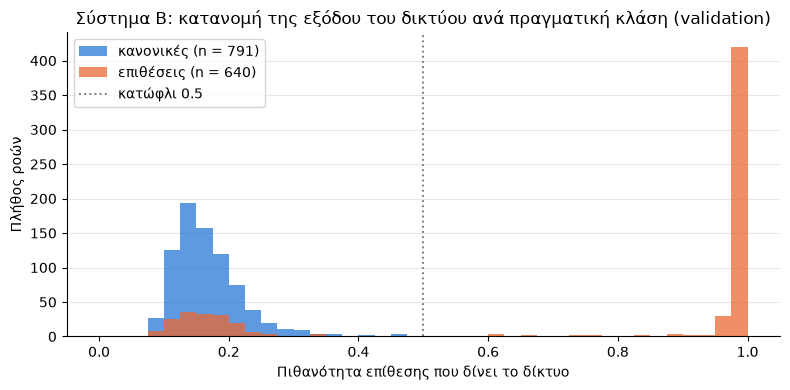

In [7]:
rest = rule_pred == 0
nn_pred = (p_nn >= 0.5).astype(int)
unknown = X["val"][:, short.index("browser_type_Unknown")] == 1 if "browser_type_Unknown" in short else np.zeros(len(rest), bool)
extra = (nn_pred == 1) & rest
print(f"Ροές validation: {len(rest)} | ο κανόνας λέει «επίθεση» σε {int((~rest).sum())}, «κανονική» σε {int(rest.sum())}")
print(f"Ίδια απόφαση δικτύου και κανόνα: {(nn_pred == rule_pred).mean():.1%}")
print(f"  το δίκτυο λέει «επίθεση» και ο κανόνας «κανονική»: {int(extra.sum())} ροές "
      f"(πραγματικές επιθέσεις: {int((extra & (y['val'] == 1)).sum())} | με browser Unknown: {int((extra & unknown).sum())})")
print(f"  ο κανόνας λέει «επίθεση» και το δίκτυο «κανονική»: {int(((nn_pred == 0) & ~rest).sum())} ροές")
print(f"\nΣτις {int(rest.sum())} ροές που ο κανόνας λέει «κανονική», οι {int(y['val'][rest].sum())} είναι στην πραγματικότητα επιθέσεις "
      f"({y['val'][rest].mean():.1%}). Το δίκτυο βρίσκει τις {int((extra & (y['val'] == 1)).sum())}.")
inside = {name: roc_auc_score(y["val"][rest], p[rest]) for name, p in {**p_val, NN: p_nn}.items() if name != RULE}
print("ROC-AUC μέσα σε αυτή την ομάδα (0.5 = τυχαία μαντεψιά):")
print(pd.Series(inside).round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 1, 41)
ax.hist(p_nn[y["val"] == 0], bins=bins, color="#2a78d6", alpha=0.75, label=f"κανονικές (n = {int((y['val'] == 0).sum())})")
ax.hist(p_nn[y["val"] == 1], bins=bins, color="#eb6834", alpha=0.75, label=f"επιθέσεις (n = {int((y['val'] == 1).sum())})")
ax.axvline(0.5, color="gray", ls=":", lw=1.4, label="κατώφλι 0.5")
ax.set_xlabel("Πιθανότητα επίθεσης που δίνει το δίκτυο"); ax.set_ylabel("Πλήθος ροών")
ax.set_title("Σύστημα Β: κατανομή της εξόδου του δικτύου ανά πραγματική κλάση (validation)")
ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True); ax.spines[["top", "right"]].set_visible(False); ax.legend()
plt.tight_layout(); plt.savefig(FIG + "B03_intrusion_probability_distribution.png", dpi=200); plt.show()